# Import


In [1]:
# General
import os
import numpy as np
import matplotlib.pyplot as plt
import random
import time
import sys


# model
import tensorflow
import tensorflow as tf
import pickle

import keras
from keras.models import Sequential
# from gradient_accumulator import GradientAccumulateModel

from tensorflow.keras import backend as K


from keras.layers import Add, GlobalAveragePooling2D,Dense, Flatten, Conv2D, Lambda,Input, BatchNormalization, Activation
from tensorflow.keras.utils import Sequence
from keras.utils import to_categorical
# from keras.callbacks import TensorBoard
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras import *
# from tensorflow.keras import layers as Layers
from tensorflow.keras.layers import *
from keras.activations import relu
from tensorflow.keras.datasets import cifar100
from tensorflow.keras.layers import *
from tensorflow.keras import layers, models

# from tensorflow.keras.layers import Add, GlobalAveragePooling2D,Dense, Flatten, Conv2D, Lambda,	Input, BatchNormalization, Activation
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# from keras.utils import to_categorical
from tensorflow.keras.optimizers import *
from tensorflow.keras.callbacks import *
from tensorflow.keras.callbacks import TensorBoard, ModelCheckpoint,EarlyStopping,ReduceLROnPlateau,LambdaCallback

2024-06-09 10:08:56.824756: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-06-09 10:08:56.824896: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-06-09 10:08:56.945949: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Config

In [2]:
policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)
tf.config.optimizer.set_jit(True)

In [3]:
sys.path.append('/kaggle/input/resnet-34/')

weight_decay = 1e-4
lr=[5e-3,1e-3,5e-4,1e-4]
num_classes = 100
dropout_rate=0.
BATCH_SIZE = 32
IMG_SIZE = 32
optimizer = AdamW
epoch = 5
loss='categorical_crossentropy'

# Define the directory path
model_dir = "/kaggle/working/"

epoch = 4  # 5th epoch (0-indexed)
batch = 30  # st batch (0-indexed)
layer = 27 # 28th layer (0-indexed)

# Data + Cutmix Augmentation

In [4]:
BATCH_SIZE = 32
IMG_SIZE =32
num_classes = 100


(X_train, y_train), (X_test, y_test) = cifar100.load_data()


y_train = to_categorical(y_train, num_classes=num_classes)
y_test = to_categorical(y_test, num_classes=num_classes)


X_train = X_train.astype('float32')
X_test = X_test.astype('float32')


X_train /= 255.
X_test /= 255.


steps = int(X_train.shape[0] / BATCH_SIZE)
steps_per_epoch = len(X_train) // BATCH_SIZE


datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
)


class CutMixImageDataGenerator():
    def __init__(self, generator1, generator2, img_size, batch_size):
        self.batch_index = 0
        self.samples = generator1.n
        self.generator1 = generator1
        self.generator2 = generator2
        self.img_size = img_size
        self.batch_size = batch_size

    def reset_index(self):
        self.generator1._set_index_array()
        self.generator2._set_index_array()

    def reset(self):
        self.batch_index = 0
        self.generator1.reset()
        self.generator2.reset()
        self.reset_index()

    def get_steps_per_epoch(self):
        quotient, remainder = divmod(self.samples, self.batch_size)
        return (quotient + 1) if remainder else quotient

    def __len__(self):
        return self.get_steps_per_epoch()

    def __next__(self):
        if self.batch_index == 0:
            self.reset()

        crt_idx = self.batch_index * self.batch_size
        if crt_idx >= self.samples:
            self.batch_index = 0
            raise StopIteration

        reshape_size = self.batch_size
        last_step_start_idx = (self.get_steps_per_epoch() - 1) * self.batch_size
        if crt_idx == last_step_start_idx:
            reshape_size = self.samples - last_step_start_idx

        X_1, y_1 = self.generator1.__next__()
        X_2, y_2 = self.generator2.__next__()

        cut_ratio = np.random.beta(a=1, b=1, size=reshape_size)
        cut_ratio = np.clip(cut_ratio, 0.3, 0.7)

        label_ratio = cut_ratio.reshape(reshape_size, 1)
        cut_img = X_2

        X = X_1.copy()
        for i in range(reshape_size):
            cut_size = int((self.img_size - 1) * cut_ratio[i])
            y1 = tf.random.uniform(shape=[], minval=0, maxval=(self.img_size - 1) - cut_size, dtype=tf.int32).numpy()
            x1 = tf.random.uniform(shape=[], minval=0, maxval=(self.img_size - 1) - cut_size, dtype=tf.int32).numpy()
            y2 = y1 + cut_size
            x2 = x1 + cut_size
            cut_arr = cut_img[i][y1:y2, x1:x2]
            X[i][y1:y2, x1:x2] = cut_arr

        y = y_1 * (1 - (label_ratio ** 2)) + y_2 * (label_ratio ** 2)
        self.batch_index += 1
        return X, y

    def __iter__(self):
        return self

train_generator1 = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
train_generator2 = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)

train_generator = CutMixImageDataGenerator(
    generator1=train_generator1,
    generator2=train_generator2,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

def generator_wrapper(generator):
    first_run = True
    while True:
        try:
            X, y = next(generator)
            if first_run:
                print(f'X shape: {X.shape}, y shape: {y.shape}')
                first_run = False  # Set the flag to False after printing
            if X.shape[0] == BATCH_SIZE:
                yield X, y
            elif X.shape[0] < BATCH_SIZE:
                # Pad the batch if it is smaller than BATCH_SIZE
                X = np.pad(X, ((0, BATCH_SIZE - X.shape[0]), (0, 0), (0, 0), (0, 0)), 'constant')
                y = np.pad(y, ((0, BATCH_SIZE - y.shape[0]), (0, 0)), 'constant')
                yield X, y
        except StopIteration:
            generator.reset()

train_ds = tf.data.Dataset.from_generator(
    lambda: generator_wrapper(train_generator),
    output_signature=(
        tf.TensorSpec(shape=(BATCH_SIZE, IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
        tf.TensorSpec(shape=(BATCH_SIZE, num_classes), dtype=tf.float32),
    )
)

train_ds = (train_ds
            .shuffle(1024)
            .cache()
            .repeat()
            .prefetch(buffer_size=tf.data.experimental.AUTOTUNE))
# model_cutmix = ResNet34()

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step


# Model (ResNet)

In [5]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.layers import DepthwiseConv2D


class BottleNeck(tf.keras.Model):
    expansion = 4

    def __init__(self, in_channels, out_channels, strides=1, dropout_rate=dropout_rate):
        super(BottleNeck, self).__init__()
        self.conv1 = layers.Conv2D(out_channels, kernel_size=1, use_bias=False)
        self.bn1 = layers.BatchNormalization()
        self.dropout1 = layers.Dropout(dropout_rate)

        # Depthwise convolution followed by pointwise convolution
        self.depthwise_conv = layers.DepthwiseConv2D(kernel_size=3, strides=strides, padding='same', use_bias=False)
        self.pointwise_conv = layers.Conv2D(out_channels, kernel_size=1, use_bias=False)
        # self.conv2 = layers.Conv2D(out_channels, kernel_size=3, strides=strides, padding='same', use_bias=False)
        self.bn2 = layers.BatchNormalization()
        self.dropout2 = layers.Dropout(dropout_rate)


        self.conv3 = layers.Conv2D(self.expansion*out_channels, kernel_size=1, use_bias=False)
        self.bn3 = layers.BatchNormalization()
        self.dropout3 = layers.Dropout(dropout_rate)

        if strides != 1 or in_channels != self.expansion*out_channels:
            self.shortcut = tf.keras.Sequential([
                layers.Conv2D(self.expansion*out_channels, kernel_size=1, strides=strides, use_bias=False),
                layers.BatchNormalization()
            ])
        else:
            self.shortcut = lambda x: x

    def call(self, x, training=True):
        out = tf.keras.activations.relu(self.bn1(self.conv1(x), training=training))
        out = self.dropout1(out, training=training)


        # out = tf.keras.activations.relu(self.bn2(self.conv2(out), training=training))

        out = tf.keras.activations.relu(self.bn2(self.pointwise_conv(self.depthwise_conv(out)), training=training))

        out = self.dropout2(out, training=training)


        out = self.bn3(self.conv3(out), training=training)
        out = self.dropout3(out, training=training)


        out = layers.add([self.shortcut(x), out])
        out = tf.keras.activations.relu(out)
        return out

class BuildResNet(tf.keras.Model):
    def __init__(self, block, num_blocks, num_classes, dropout_rate=dropout_rate):
        super(BuildResNet, self).__init__()
        self.in_channels = 64

        self.conv1 = layers.Conv2D(64, kernel_size=3, strides=1, padding='same', use_bias=False)
        self.bn1 = layers.BatchNormalization()
        self.layer1 = self._make_layer(block, 64, num_blocks[0], strides=1, dropout_rate=dropout_rate)
        self.layer2 = self._make_layer(block, 64, num_blocks[1], strides=2, dropout_rate=dropout_rate)
        self.layer3 = self._make_layer(block, 128, num_blocks[2], strides=2, dropout_rate=dropout_rate)
        self.layer4 = self._make_layer(block, 256, num_blocks[3], strides=2, dropout_rate=dropout_rate)
        self.avg_pool2d = layers.AveragePooling2D(pool_size=4)
        self.flatten = layers.Flatten()
        self.fc = layers.Dense(num_classes, activation='softmax')

    def call(self, x, training=True):
        out = tf.keras.activations.relu(self.bn1(self.conv1(x), training=training))
        out = self.layer1(out, training=training)
        out = self.layer2(out, training=training)
        out = self.layer3(out, training=training)
        out = self.layer4(out, training=training)
        out = self.avg_pool2d(out)
        out = self.flatten(out)
        out = self.fc(out)
        return out

    def _make_layer(self, block, out_channels, num_blocks, strides, dropout_rate):
        stride = [strides] + [1]*(num_blocks-1)
        layers_list = []
        for s in stride:
            layers_list.append(block(self.in_channels, out_channels, s, dropout_rate))
            self.in_channels = out_channels * block.expansion
        return tf.keras.Sequential(layers_list)

def ResNet50(num_classes=num_classes, dropout_rate=dropout_rate):
    return BuildResNet(BottleNeck, [3, 4, 6, 3], num_classes,dropout_rate)


# training with cutmix

In [6]:
class GCAdamW(AdamW):
    def __init__(self, learning_rate, weight_decay, **kwargs):
        super(GCAdamW, self).__init__(learning_rate, weight_decay, **kwargs)

    def get_gradients(self, loss, params):
        # Compute the gradients
        grads = super().get_gradients(loss, params)

        # Centralize the gradients
        centralized_grads = []
        for grad in grads:
            if grad is not None:
                grad_len = len(grad.shape)
                if grad_len > 1:
                    axis = list(range(grad_len - 1))
                    grad -= tf.reduce_mean(grad, axis=axis, keepdims=True)
            centralized_grads.append(grad)

        return centralized_grads

In [7]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[0], weight_decay=1e-4)



# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])



In [8]:
# layer = 27
# specific_gradients_1 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients_2.shape)
# l1 = np.array(specific_gradients_1).flatten()
# d1 = []
# for i in range(1,len(l1)):
#     d1.append(np.linalg.norm(l1[i-1] - l1[i]).item())
# print(d1)

In [9]:
d1 = [2.720978227443993e-05, 2.2761814761906862e-06, 0.00054320995695889, 0.0006836012471467257, 0.0006523707415908575, 0.0004411051922943443, 2.230601239716634e-05, 0.0014410968869924545, 0.002289240015670657, 0.001403644448146224, 0.0005478723323903978, 5.3945132094668224e-05, 0.00012943724868819118, 5.1032220653723925e-05, 1.8295209883945063e-05, 9.8928197985515e-05, 0.0006014130776748061, 0.0003801087150350213, 0.00033628352684900165, 0.00024363705597352237, 0.0018020474817603827, 0.003513841424137354, 0.0018448068294674158, 7.177337829489261e-05, 0.0002019927924266085, 0.00021914037643000484, 0.0007056930917315185, 0.0010665626032277942, 0.00026582370628602803, 5.567575863096863e-05, 0.0008163779857568443, 0.0020224808249622583, 0.0011912444606423378, 4.485563113121316e-05, 8.940543921198696e-05, 0.000258133775787428, 0.0004336951533332467, 0.0005022407276555896, 0.000801320536993444, 0.00017178672715090215, 0.0004642243147827685, 0.0013563560787588358, 5.19677996635437e-05, 0.0015926302876323462, 0.0012594748986884952, 0.00034574721939861774, 0.001018635230138898, 9.25636850297451e-05, 0.0010913851438090205, 0.0003027655475307256, 5.0185772124677896e-05, 0.00016782125749159604, 0.0005091907223686576, 0.0008975797099992633, 0.0005880738026462495, 0.0007384499767795205, 0.0006353461067192256, 0.001376916654407978, 0.00048784061800688505, 1.3394339475780725e-05, 0.0008763840305618942, 0.0007551857270300388, 0.0003081071190536022]

In [10]:
model = ResNet50()

optimizer = GCAdamW(learning_rate=lr[1], weight_decay=1e-4)

model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])



class GradientCalcCallback(Callback):
    def __init__(self, data, batch_size=32):
        super().__init__()
        self.data = data
        self.batch_size = batch_size
        self.epoch_gradients = []
        self.current_epoch_gradients = []

    def on_batch_end(self, batch, logs=None):
        x_batch, y_batch = self.data
        with tf.GradientTape() as tape:
            predictions = self.model(x_batch, training=True)
            loss = self.model.compiled_loss(y_batch, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        
        # Store gradients
        batch_gradients = [g.numpy() for g in gradients]
        self.current_epoch_gradients.append(batch_gradients)

    def on_epoch_end(self, epoch, logs=None):
        # Save the gradients of the entire epoch
        self.epoch_gradients.append(self.current_epoch_gradients)
        self.current_epoch_gradients = []

callback = GradientCalcCallback(data=(X_train[:32], y_train[:32]))

model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])

Epoch 1/5


I0000 00:00:1717927785.467123     104 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


X shape: (32, 32, 32, 3), y shape: (32, 100)


/opt/conda/lib/python3.10/site-packages/keras/src/backend/tensorflow/trainer.py:603: UserWarning: `model.compiled_loss()` is deprecated. Instead, use `model.compute_loss(x, y, y_pred, sample_weight)`.
  warnings.warn(


300/300 ━━━━━━━━━━━━━━━━━━━━ 336s 676ms/step - accuracy: 0.0187 - loss: 5.1326
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 204s 680ms/step - accuracy: 0.0433 - loss: 4.5185
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 205s 685ms/step - accuracy: 0.0571 - loss: 4.3115
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 201s 670ms/step - accuracy: 0.0751 - loss: 4.2171
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 201s 670ms/step - accuracy: 0.0791 - loss: 4.1542


In [11]:
layer= 27
specific_gradients_2 = callback.epoch_gradients[epoch][batch][layer]
# print("Shape of specific gradients:", specific_gradients_2.shape)
l2 = np.array(specific_gradients_2).flatten()
d2 = []
for i in range(1,len(l2)):
    d2.append(np.linalg.norm(l2[i-1] - l2[i]).item())
print(d2)

[0.01731983758509159, 0.0158565491437912, 0.02766129933297634, 0.016045885160565376, 0.0029517195653170347, 0.014689045026898384, 0.008578832261264324, 0.004053534008562565, 0.011402787640690804, 0.017117470502853394, 7.992528844624758e-05, 0.0047500054351985455, 0.0002506994642317295, 0.004099630285054445, 0.005611910484731197, 0.003174262121319771, 0.0016743374289944768, 0.0021099208388477564, 0.005194837227463722, 0.022403353825211525, 0.020947642624378204, 0.01483985036611557, 0.013777432031929493, 0.0028882811311632395, 0.002524162642657757, 0.0007312196539714932, 0.0021640779450535774, 0.009387621656060219, 0.006715760566294193, 0.007661486975848675, 0.0033629601821303368, 0.005529981106519699, 0.008769111707806587, 0.007767269853502512, 0.0009745564311742783, 0.0038836048915982246, 0.00261590420268476, 0.006090915761888027, 0.0078846774995327, 0.010079637169837952, 0.0030932514928281307, 0.0035251430235803127, 0.010760427452623844, 0.005344596691429615, 0.01577000319957733, 0.01

In [12]:
# d2 = [0.0035819876939058304, 0.004368454217910767, 0.0040826573967933655, 0.0019911988638341427, 0.0005788553389720619, 0.0021109613589942455, 0.0032175625674426556, 3.8090161979198456e-05, 0.0005557811819016933, 0.003317986847832799, 0.002500229049474001, 0.004136208910495043, 0.00525900861248374, 0.004133791662752628, 0.002390678506344557, 0.001863974379375577, 0.00035186432069167495, 0.012762912549078465, 0.014094831421971321, 0.0031121864449232817, 0.00012159813195466995, 0.004459542687982321, 0.021079864352941513, 0.003062853589653969, 0.008857562206685543, 0.0036012199707329273, 0.0020571649074554443, 0.0016129419673234224, 0.0021691862493753433, 0.003821736201643944, 0.0012646177783608437, 0.004024455323815346, 0.0006244294345378876, 0.004405170679092407, 0.00568268122151494, 0.007554084528237581, 0.005640209652483463, 0.003333034925162792, 0.009860444813966751, 0.0077323149889707565, 2.4533888790756464e-05, 0.0032088360749185085, 0.004059119615703821, 0.0002667008084245026, 0.005251370370388031, 0.010290773585438728, 0.004323423840105534, 0.004899103194475174, 0.005899190902709961, 0.0050284056924283504, 0.0009873481467366219, 0.0050398483872413635, 0.0016633181367069483, 0.0029571428894996643, 0.009490815922617912, 0.007018829230219126, 0.01366336178034544, 0.013491862453520298, 0.004296852741390467, 0.00112318922765553, 0.0036367217544466257, 0.005222776904702187, 0.0001557823270559311]

In [13]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[2], weight_decay=1e-4)

# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])



# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])

In [14]:
# specific_gradients_3 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients_3.shape)
# l3 = np.array(specific_gradients_3).flatten()
# d3 = []
# for i in range(1,len(l3)):
#     d3.append(np.linalg.norm(l3[i-1] - l3[i]).item())
# print(d3)

In [15]:
d3 = [0.002165118930861354, 0.003836067859083414, 0.006600395310670137, 0.006093957461416721, 0.003005648497492075, 5.8484612964093685e-05, 0.005125208757817745, 0.010122817009687424, 0.005035684444010258, 0.005969462916254997, 0.002084746491163969, 0.005931001156568527, 0.003976282197982073, 0.0029579210095107555, 0.001047970145009458, 0.0030985537450760603, 0.007119947113096714, 0.003468734910711646, 0.0013171887258067727, 0.003345411503687501, 0.0009767109295353293, 0.008142005652189255, 0.003766808658838272, 0.011270311661064625, 0.0026790860574692488, 0.004159693140536547, 0.008406654000282288, 0.007471232209354639, 5.203283217269927e-05, 0.0038596149533987045, 0.003379135625436902, 0.010041452012956142, 0.01222867053002119, 0.001563141937367618, 0.009343192912638187, 0.018839670345187187, 0.0037863629404455423, 0.003317886730656028, 0.007119749207049608, 0.014561212621629238, 0.00685522286221385, 0.004501139745116234, 0.012120729312300682, 0.004031728021800518, 0.005909401923418045, 0.008841585367918015, 0.003427603282034397, 0.002962132915854454, 0.0018545142374932766, 0.0003997855819761753, 0.005280912853777409, 0.004018297418951988, 0.0048782420344650745, 0.0017767582321539521, 0.002431360771879554, 0.0027745526749640703, 0.003610404208302498, 0.0056650652550160885, 0.003982351161539555, 0.0006087389774620533, 0.001423385227099061, 0.008587734773755074, 0.007008638698607683]

In [16]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[3], weight_decay=1e-4)



# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])

In [17]:
# specific_gradients_4 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients.shape)
# l4 = np.array(specific_gradients_4).flatten()
# d4 = []
# for i in range(1,len(l4)):
#     d4.append(np.linalg.norm(l4[i-1] - l4[i]).item())
# print(d4)

In [18]:
d4 = [0.1851288378238678, 0.044442348182201385, 0.12991656363010406, 0.012724371626973152, 0.012997465208172798, 0.0044919997453689575, 0.0982782319188118, 0.06594125926494598, 0.02454438991844654, 0.09296829998493195, 0.10492870956659317, 0.060936763882637024, 0.13356968760490417, 0.05660613253712654, 0.03023318573832512, 0.03555091843008995, 0.06314404308795929, 0.046843744814395905, 0.018092406913638115, 0.003907022066414356, 0.05130678787827492, 0.038264211267232895, 0.02327527105808258, 0.004673518240451813, 0.02407201938331127, 0.07757596671581268, 0.12466668337583542, 0.043531518429517746, 0.0040576583705842495, 0.03979593887925148, 0.06298066675662994, 0.037022024393081665, 0.0004267953336238861, 0.011296572163701057, 0.04099280759692192, 0.04731068015098572, 0.03489310294389725, 0.04144040122628212, 0.005784514360129833, 0.11665569990873337, 0.06875142455101013, 0.06211063265800476, 0.02211528643965721, 0.053427182137966156, 0.027416691184043884, 0.03726509213447571, 0.07799356430768967, 0.03296326845884323, 0.02690238505601883, 0.019369155168533325, 0.051877327263355255, 0.010398298501968384, 0.020493125542998314, 0.02237679436802864, 0.041425805538892746, 0.06712350249290466, 0.034248847514390945, 0.0848253071308136, 0.1445188820362091, 0.09533369541168213, 0.040625810623168945, 0.08669506013393402, 0.14243704080581665]


# data Augemtn

In [19]:
# BATCH_SIZE = 32
# IMG_SIZE =32
# num_classes = 100


# (X_train, y_train), (X_test, y_test) = cifar100.load_data()

# y_train = to_categorical(y_train, num_classes=num_classes)
# y_test = to_categorical(y_test, num_classes=num_classes)


# X_train = X_train.astype('float32')
# X_test = X_test.astype('float32')


# X_train /= 255.
# X_test /= 255.



# steps = int(X_train.shape[0] / BATCH_SIZE)

# datagen = ImageDataGenerator(
#     rotation_range=15,
#     width_shift_range=0.1,
#     height_shift_range=0.1,
#     horizontal_flip=True,
# )
# train_generator = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)  # generate augmented data from training set

# train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))

# # create the dataset pipeline
# train_ds = (train_ds
#             .shuffle(1024)
#             .cache()
#             .repeat()
#             .batch(BATCH_SIZE)
#             .prefetch(buffer_size=tf.data.experimental.AUTOTUNE))

In [20]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[0], weight_decay=1e-4)



# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])

In [21]:
# specific_gradients_11 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients.shape)
# l11 = np.array(specific_gradients_11).flatten()
# d11 = []
# for i in range(1,len(l11)):
#     d11.append(np.linalg.norm(l11[i-1] - l11[i]).item())
# print(d11)

In [22]:
d11 = [0.00038561291876249015, 0.00034052328555844724, 0.00030742664239369333, 2.349475835217163e-06, 9.503781620878726e-05, 7.312129309866577e-05, 0.00010188988380832598, 9.65454091783613e-05, 0.000379349134163931, 0.0008764808299019933, 0.0014622043818235397, 0.0007564481347799301, 0.0010046124225482345, 0.0013661946868523955, 0.0013602740364149213, 2.4687444238224998e-05, 0.00023584293376188725, 0.0001788191730156541, 0.00020455977937672287, 0.0020379137713462114, 0.002004242269322276, 0.00019338082347530872, 0.000282028631772846, 3.175779420416802e-05, 0.0004192759224679321, 2.7484784368425608e-06, 0.00012906572374049574, 4.1810581024037674e-05, 0.0003566027735359967, 0.0017265774076804519, 0.0015408137114718556, 0.0005614577676169574, 0.00045060543925501406, 0.00018765096319839358, 5.952620995230973e-05, 7.014076982159168e-05, 0.0003870731161441654, 0.0003650885191746056, 0.0007849451503716409, 0.0008443392580375075, 0.000772939354646951, 0.0005674021085724235, 0.0005374837783165276, 0.000373102753655985, 0.00010605622082948685, 8.669593808008358e-05, 0.0006359759136103094, 0.000671814545057714, 0.00032105407444760203, 9.905098704621196e-05, 0.0002807797282002866, 0.0002189288497902453, 9.115318243857473e-05, 0.00018660612113308161, 0.0004761461168527603, 0.0003520945319905877, 4.8330111894756556e-06, 0.0003454659308772534, 0.0003177598991896957, 8.933874778449535e-05, 0.0002901686239056289, 0.0004635229706764221, 0.00012764407438226044]


In [23]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[1], weight_decay=1e-4)

# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])


In [24]:
# specific_gradients_12 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients.shape)
# l12 = np.array(specific_gradients_12).flatten()
# d12 = []
# for i in range(1,len(l12)):
#     d12.append(np.linalg.norm(l12[i-1] - l12[i]).item())
# print(d12)

In [25]:
d12 = [0.003912328742444515, 0.00032353599090129137, 0.0002611228555906564, 4.012943827547133e-05, 0.0003023962490260601, 0.0033006402663886547, 0.0005716201849281788, 0.006222839001566172, 0.0037800034042447805, 0.002169298008084297, 0.0013038144679740071, 0.00035981161636300385, 0.0019861357286572456, 0.0014164596796035767, 0.0035455641336739063, 0.003408086020499468, 0.0017634311225265265, 0.0004453000146895647, 0.003224784042686224, 0.007359227165579796, 0.0020705994684249163, 0.0016850577667355537, 0.0032769462559372187, 0.004144650883972645, 0.000879070139490068, 0.0034857592545449734, 0.0012525285128504038, 0.002354052849113941, 0.004566915798932314, 0.00038606789894402027, 0.0025391976814717054, 0.004613941069692373, 0.005360142793506384, 0.0025850371457636356, 0.000735882727894932, 0.0004368615336716175, 0.0007527398411184549, 0.001346952049061656, 0.000262671266682446, 0.0032295195851475, 0.002571576274931431, 0.006286236457526684, 0.006951947696506977, 0.002667831489816308, 0.0026775936130434275, 0.0007909801788628101, 0.002582746557891369, 0.0016238916432484984, 0.0003215184260625392, 0.0002014174242503941, 0.0032511455938220024, 0.0017301004845649004, 0.008399225771427155, 0.0072615984827280045, 0.0031185306143015623, 0.001010835636407137, 0.0009035165421664715, 0.0016714506782591343, 0.006709268316626549, 0.00813908502459526, 0.0076504237949848175, 0.01074832584708929, 0.003698581364005804]

In [26]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[2], weight_decay=1e-4)

# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])


In [27]:
# specific_gradients_13 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients.shape)
# l13 = np.array(specific_gradients_13).flatten()
# d13 = []
# for i in range(1,len(l13)):
#     d13.append(np.linalg.norm(l13[i-1] - l13[i]).item())
# print(d13)

In [28]:
d13 = [0.001508796587586403, 0.002885846421122551, 0.0011387206614017487, 0.003957431763410568, 0.007929185405373573, 0.002289710333570838, 0.007358351722359657, 0.006533394102007151, 0.002397571224719286, 0.0017359908670186996, 0.004377574659883976, 0.0024018127005547285, 0.0013587470166385174, 0.002600982552394271, 0.001014533918350935, 0.0015581287443637848, 0.0050422921776771545, 0.00919235497713089, 0.0024647442623972893, 0.011161044239997864, 5.8067962527275085e-06, 0.00830838456749916, 0.00559055944904685, 0.000637294608168304, 0.009854634292423725, 0.009279478341341019, 0.0017361447680741549, 0.002606842201203108, 0.0028495504520833492, 0.0026013071183115244, 0.001542815938591957, 0.0025436372961848974, 0.0029269990045577288, 0.0031255134381353855, 0.004900906700640917, 0.004255594685673714, 0.002099151723086834, 0.0102936290204525, 0.009554420597851276, 0.004017103463411331, 0.0009061652235686779, 0.002869263058528304, 0.0023726350627839565, 0.0014253294793888927, 0.0044271196238696575, 0.00416969507932663, 0.007594590075314045, 0.007138572167605162, 0.00040957413148134947, 0.004071640782058239, 0.003512553870677948, 0.0022588283754885197, 0.0034514600411057472, 0.001594596542418003, 0.004332410171627998, 0.0007816090947017074, 0.0017684075282886624, 0.001158878905698657, 0.001966801704838872, 0.009006982669234276, 0.0066874646581709385, 0.0008680840255692601, 0.0020370883867144585]


In [29]:
# model = ResNet50()

# optimizer = GCAdamW(learning_rate=lr[3], weight_decay=1e-4)

# model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

# class GradientCalcCallback(Callback):
#     def __init__(self, data, batch_size=128):
#         super().__init__()
#         self.data = data
#         self.batch_size = batch_size
#         self.epoch_gradients = []
#         self.current_epoch_gradients = []

#     def on_batch_end(self, batch, logs=None):
#         x_batch, y_batch = self.data
#         with tf.GradientTape() as tape:
#             predictions = self.model(x_batch, training=True)
#             loss = self.model.compiled_loss(y_batch, predictions)
#         gradients = tape.gradient(loss, self.model.trainable_variables)
        
#         # Store gradients
#         batch_gradients = [g.numpy() for g in gradients]
#         self.current_epoch_gradients.append(batch_gradients)

#     def on_epoch_end(self, epoch, logs=None):
#         # Save the gradients of the entire epoch
#         self.epoch_gradients.append(self.current_epoch_gradients)
#         self.current_epoch_gradients = []

# callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

# model.fit(train_ds, epochs=5,steps_per_epoch = 300, batch_size=32, callbacks=[callback])

In [30]:
# specific_gradients_14 = callback.epoch_gradients[epoch][batch][layer]
# # print("Shape of specific gradients:", specific_gradients.shape)
# l14 = np.array(specific_gradients_14).flatten()
# d14 = []
# for i in range(1,len(l14)):
#     d14.append(np.linalg.norm(l14[i-1] - l14[i]).item())
# print(d14)

In [31]:
d14 = [0.00471075251698494, 0.01427236944437027, 0.1475616693496704, 0.023745320737361908, 0.01793839782476425, 0.08996520936489105, 0.006802154704928398, 0.0561797171831131, 0.043667472898960114, 0.11963945627212524, 0.11430453509092331, 0.0590401217341423, 0.039126116782426834, 0.018241411074995995, 0.010455852374434471, 0.03800719231367111, 0.055299125611782074, 0.041118327528238297, 0.05578603595495224, 0.046196743845939636, 0.020839601755142212, 0.032994676381349564, 0.030529940500855446, 0.08088403940200806, 0.08052510768175125, 0.038230400532484055, 0.0025426894426345825, 0.025572121143341064, 0.03061000443994999, 0.03936590254306793, 3.648083657026291e-05, 0.08437705785036087, 0.05541824549436569, 0.025106504559516907, 0.11378943175077438, 0.09290122985839844, 0.01695322059094906, 0.06117893010377884, 0.1749381124973297, 0.08873537927865982, 0.06843197345733643, 0.06720313429832458, 0.035926271229982376, 0.10755705833435059, 0.05986888334155083, 0.06202547624707222, 0.031093209981918335, 0.011257138103246689, 0.05340978875756264, 0.06435894966125488, 0.059117116034030914, 0.04613898694515228, 0.03261754661798477, 0.02243710681796074, 0.028299786150455475, 0.005669392645359039, 0.15776678919792175, 0.14196345210075378, 0.14135244488716125, 0.0683244913816452, 0.06322509050369263, 0.08581910282373428, 0.10830935835838318]

#### Convmixer 10

#### convmixer 100

In [32]:
min_curve_cutmix = []
max_curve_cutmix = []
for i in range(len(d1)):
    min_curve_cutmix.append(np.min([d1[i], d2[i], d3[i], d4[i]]))
    max_curve_cutmix.append(np.max([d1[i], d2[i], d3[i], d4[i]]))


In [33]:
min_curve = []
max_curve= []
for i in range(len(d1)):
    min_curve.append(np.min([d11[i], d12[i], d13[i], d14[i]]))
    max_curve.append(np.max([d11[i], d12[i], d13[i], d14[i]]))


# getting plots together

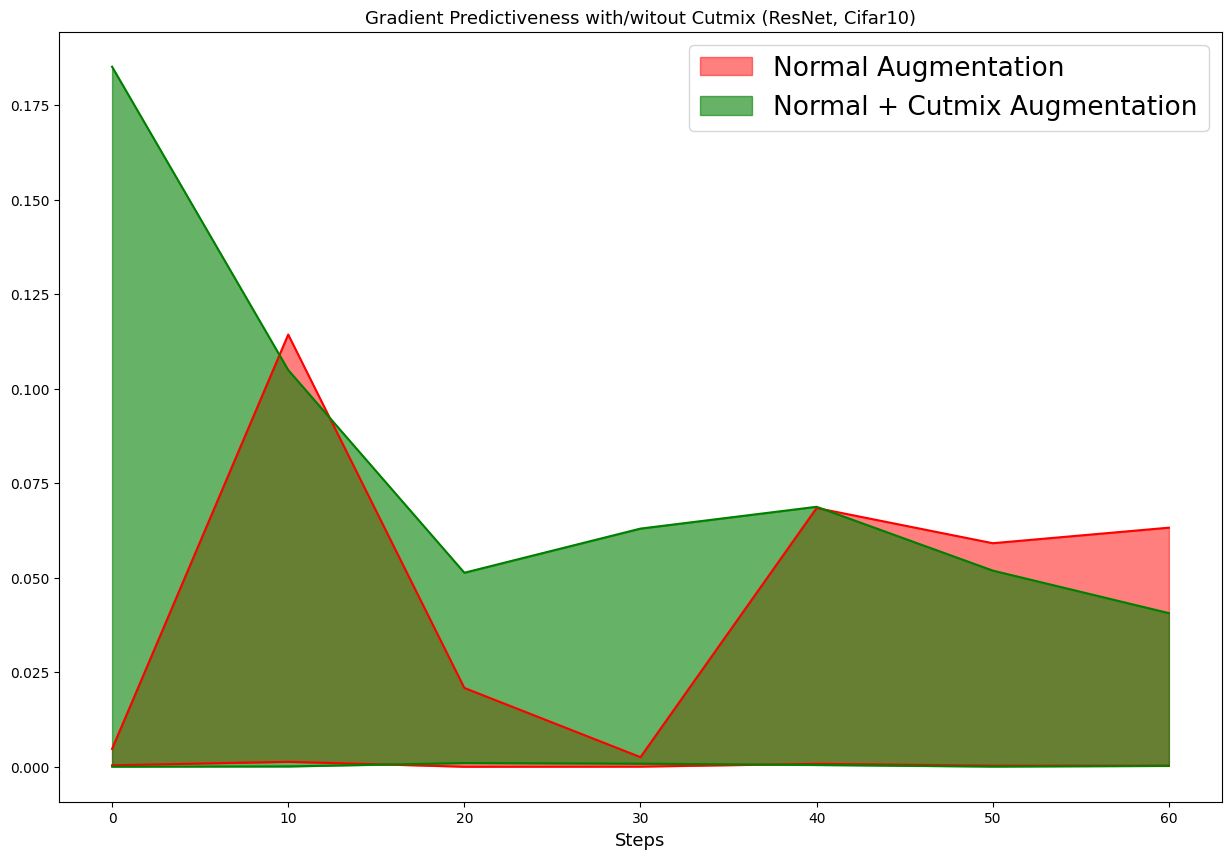

In [34]:
step = 10
steps = np.arange(0, len(min_curve), step)
plt.figure(figsize=(15, 10))
plt.fill_between(steps, min_curve[::step], max_curve[::step],
                alpha=.5, color='red', label='Normal Augmentation')
plt.plot(steps, min_curve[::step], color='red')
plt.plot(steps, max_curve[::step], color='red')

plt.fill_between(steps, min_curve_cutmix[::step], max_curve_cutmix[::step],
                alpha=0.6, color='Green', label='Normal + Cutmix Augmentation')
plt.plot(steps, min_curve_cutmix[::step], color='Green')
plt.plot(steps, max_curve_cutmix[::step], color='Green')

plt.legend(fontsize=19)
plt.title('Gradient Predictiveness', fontsize=20)

plt.xlabel('Steps', fontsize=13)
plt.title('Gradient Predictiveness with/witout Cutmix (ResNet, Cifar100)', fontsize=13)

# plt.savefig(os.path.join(figures_path, 'gradient_predictiveness.png'), dpi=500, quality=100)
plt.show()

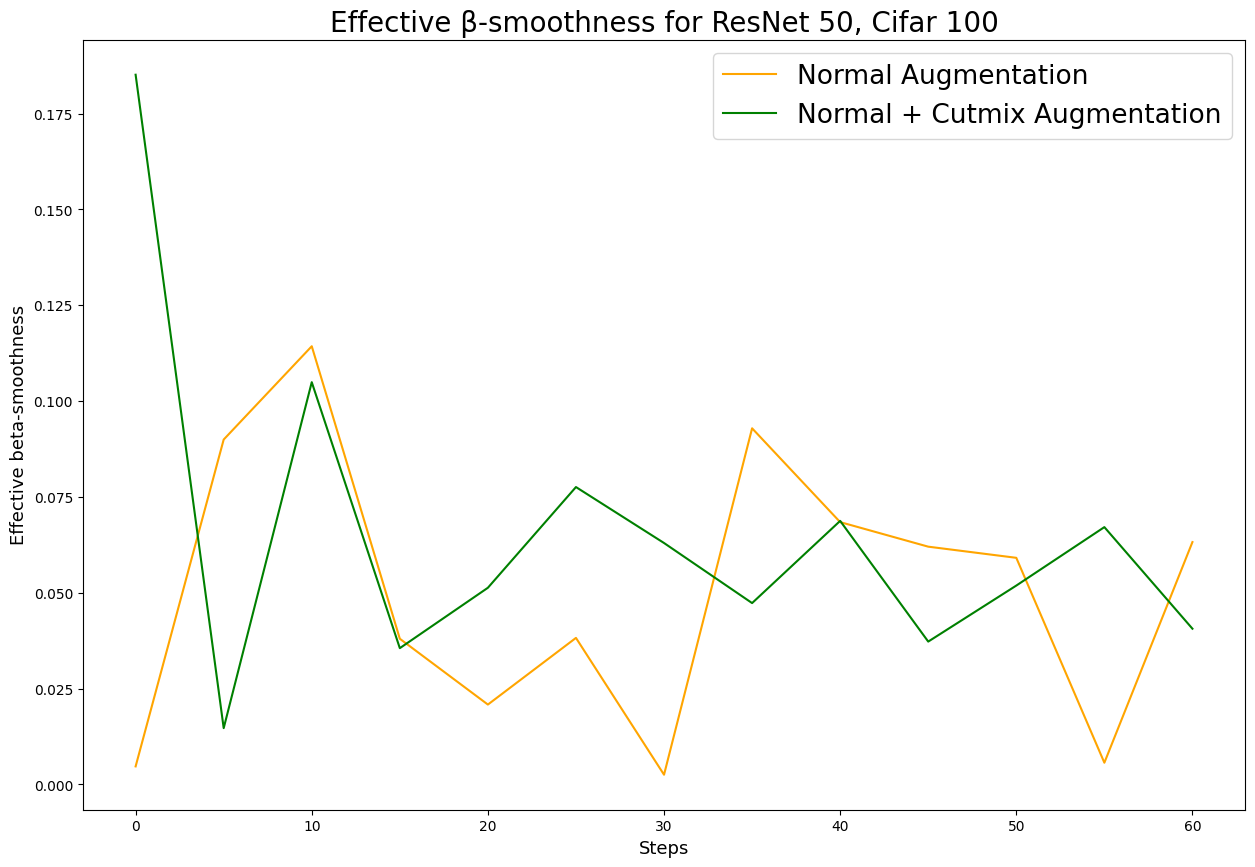

In [39]:
step = 5
steps = np.arange(0, len(min_curve), step)
plt.figure(figsize=(15, 10))

plt.plot(steps, max_curve[::step], color='orange', label='Normal Augmentation')

plt.plot(steps, max_curve_cutmix[::step], color='green', label='Normal + Cutmix Augmentation')

plt.legend(fontsize=19)
plt.title('Effective β-smoothness for ResNet 50, Cifar 100', fontsize=20)
plt.ylabel('Effective beta-smoothness', fontsize=13)
plt.xlabel('Steps', fontsize=13)
# plt.savefig(os.path.join(figures_path, 'effective_beta_smoothness.png'), dpi=500, quality=100)
plt.show()

In [36]:
d = [0.0004591941833496094, 5.2034854888916016e-05, 0.0001137852668762207, 0.00038188695907592773, 3.129243850708008e-05, 0.00040328502655029297, 4.106760025024414e-05, 0.00012290477752685547, 0.0003376007080078125, 5.2809715270996094e-05, 0.00017684698104858398, 0.00037086009979248047, 0.00019359588623046875, 0.0006878972053527832, 0.0008823871612548828, 0.000492095947265625, 0.0002008676528930664, 0.0002351999282836914, 0.00022727251052856445, 0.00020891427993774414, 0.00013506412506103516, 0.0005027055740356445, 0.0006587505340576172, 0.0004297494888305664, 0.0005853176116943359, 0.0005753636360168457, 0.00023615360260009766, 0.0003635883331298828, 4.076957702636719e-05, 0.0008884072303771973, 0.0005170106887817383, 0.00034373998641967773, 0.000832974910736084, 0.00045037269592285156, 0.0003497600555419922, 0.0005678534507751465, 0.00021636486053466797, 0.00021141767501831055, 0.00013506412506103516, 0.00022488832473754883, 0.0002593994140625, 0.0007311105728149414, 0.0003679990768432617, 0.0005180835723876953, 0.0003091096878051758, 0.0001804828643798828, 0.00012493133544921875, 0.000424802303314209, 3.618001937866211e-05, 1.817941665649414e-05, 0.00032508373260498047, 0.0003635883331298828, 0.0005359053611755371, 0.0007131695747375488, 2.4557113647460938e-05, 0.0006293654441833496, 0.00044840574264526367, 0.00027871131896972656, 0.00019532442092895508, 0.0006403326988220215, 0.0004153251647949219, 0.00020200014114379883, 0.0002484321594238281, 5.728006362915039e-05, 3.981590270996094e-05, 0.0002338886260986328, 0.0007374882698059082, 0.000754237174987793, 0.0005703568458557129, 7.253885269165039e-05, 0.0005335211753845215, 0.0004949569702148438, 1.150369644165039e-05, 0.0001195669174194336, 0.0003827810287475586, 0.00019037723541259766, 5.054473876953125e-05, 0.0003247857093811035, 0.0002149343490600586, 4.3451786041259766e-05, 0.0004210472106933594, 0.00038743019104003906, 4.088878631591797e-05, 8.344650268554688e-05, 0.0003898143768310547, 0.00023126602172851562, 0.00046896934509277344, 0.000517725944519043, 4.00543212890625e-05, 0.0002021193504333496, 0.0001907944679260254, 0.00039184093475341797, 0.0004426240921020508, 0.0008050203323364258, 0.0006209015846252441, 0.00011205673217773438, 0.00023639202117919922, 7.790327072143555e-05, 0.0003673434257507324, 0.0006529688835144043, 4.649162292480469e-05, 0.0001270771026611328, 0.00032514333724975586, 3.427267074584961e-05, 3.916025161743164e-05, 0.0004627704620361328, 0.00017410516738891602, 0.0003992319107055664, 7.450580596923828e-06, 0.000253140926361084, 0.000455319881439209, 6.198883056640625e-06, 0.000633537769317627, 0.0005456805229187012, 0.00012058019638061523, 0.00026226043701171875, 1.0728836059570312e-05, 0.00037783384323120117, 0.00038617849349975586, 0.00011742115020751953, 0.0005423426628112793, 0.00037157535552978516, 0.000209808349609375, 0.00025659799575805664, 8.845329284667969e-05, 0.0004373788833618164, 0.00048273801803588867, 0.0001348257064819336, 0.0008142590522766113, 0.0009782910346984863, 0.0001513957977294922, 0.00027740001678466797, 0.0006055831909179688, 0.0003508925437927246, 0.000758051872253418, 0.0011944770812988281, 0.0004246830940246582, 0.0005257129669189453, 0.0010809898376464844, 0.0005864500999450684, 7.849931716918945e-05, 0.000344693660736084, 0.0004889369010925293, 5.9723854064941406e-05, 0.000422060489654541, 0.0005388855934143066, 0.0002630949020385742, 0.0002048015594482422, 0.00041109323501586914, 0.00034433603286743164, 0.00043016672134399414, 4.202127456665039e-05, 0.00016987323760986328, 0.00036519765853881836, 0.00036531686782836914, 7.528066635131836e-05, 0.0002123117446899414, 0.00045621395111083984, 0.0001341700553894043, 0.00037211179733276367, 0.00016558170318603516, 6.014108657836914e-05, 0.0002671480178833008, 8.046627044677734e-05, 0.00016295909881591797, 1.615285873413086e-05, 0.000213623046875, 0.00046688318252563477, 0.0003057718276977539, 0.00012487173080444336, 7.832050323486328e-05, 0.0004298090934753418, 8.159875869750977e-05, 0.00012451410293579102, 0.00023418664932250977, 0.00021225214004516602, 0.0003927946090698242, 0.0005286931991577148, 0.000244140625, 0.0004400014877319336, 0.0007560849189758301, 0.0005388259887695312, 0.0003921985626220703, 0.00022935867309570312, 0.00010204315185546875, 0.00032383203506469727, 8.952617645263672e-05, 0.000648796558380127, 0.0007358789443969727, 0.0005606412887573242, 0.000552058219909668, 0.00043386220932006836, 0.0006425380706787109, 0.0007382631301879883, 4.3392181396484375e-05, 0.00016772747039794922, 0.00017184019088745117, 0.000704348087310791, 0.00040346384048461914, 0.000133514404296875, 0.0005873441696166992, 5.125999450683594e-05, 0.0008990764617919922, 0.00014781951904296875, 0.00018787384033203125, 0.00021189451217651367, 0.0005274415016174316, 6.943941116333008e-05, 0.0005054473876953125, 0.0007245540618896484, 0.00039398670196533203, 0.00017821788787841797, 0.00013756752014160156, 0.00038892030715942383, 0.00046539306640625, 0.00023055076599121094, 0.0008397102355957031, 0.0007613897323608398, 0.00018078088760375977, 2.1219253540039062e-05, 0.0002587437629699707, 0.00022643804550170898, 0.0003222227096557617, 0.0005707144737243652, 0.0002079010009765625, 0.0007227659225463867, 0.0008237957954406738, 9.554624557495117e-05, 0.00019872188568115234, 0.0001062154769897461, 0.0002523660659790039, 0.00026345252990722656, 0.0002275705337524414, 5.4717063903808594e-05, 0.0004864335060119629, 0.00047975778579711914, 0.0004928112030029297, 8.422136306762695e-05, 6.222724914550781e-05, 3.3974647521972656e-06, 0.00038886070251464844, 0.00012677907943725586, 2.1159648895263672e-05, 0.0003307461738586426, 0.00025331974029541016, 0.0001710653305053711, 0.00023490190505981445, 0.00027823448181152344, 0.0001545548439025879, 0.0006415843963623047, 0.00013810396194458008, 6.210803985595703e-05, 0.00018900632858276367, 0.0003356337547302246, 0.0001971125602722168, 0.00010287761688232422, 0.00029754638671875, 0.00025838613510131836, 7.075071334838867e-05, 0.00036394596099853516, 0.0004843473434448242, 0.000653386116027832, 0.000828862190246582, 0.0006799697875976562, 0.0003490447998046875, 0.0005872845649719238, 0.00029671192169189453, 0.0001385807991027832, 0.00025910139083862305, 0.00029289722442626953, 3.2782554626464844e-06, 0.00022590160369873047, 0.00012940168380737305, 0.0003553628921508789, 5.906820297241211e-05, 0.00019663572311401367, 0.00020843744277954102, 0.00010150671005249023, 1.704692840576172e-05, 0.00029528141021728516, 0.0002123713493347168, 0.0004386305809020996, 0.00032019615173339844, 0.00038552284240722656, 0.0005438923835754395, 0.0010384321212768555, 0.0007369518280029297, 0.00027304887771606445, 0.0003520846366882324, 0.0006733536720275879, 0.0006290674209594727, 0.0002709031105041504, 0.00020807981491088867, 0.0009391307830810547, 0.00017976760864257812, 7.772445678710938e-05, 8.32676887512207e-05, 6.508827209472656e-05, 3.6597251892089844e-05, 0.000424802303314209, 0.0003972053527832031, 0.00040268898010253906, 0.0001983642578125, 0.0002104043960571289, 0.00043886899948120117, 0.00024080276489257812, 0.00021499395370483398, 6.836652755737305e-05, 0.0003693103790283203, 0.000338137149810791, 0.0002630949020385742, 0.0002601742744445801, 0.00024020671844482422, 0.0006172657012939453, 0.0007383823394775391, 0.00042134523391723633, 0.0003985762596130371, 7.915496826171875e-05, 0.00029736757278442383, 0.0009198784828186035, 0.0006057024002075195, 0.0003172755241394043, 0.0007028579711914062, 0.0006702542304992676, 0.0003426671028137207, 0.00033104419708251953, 0.0003827214241027832, 0.0001074075698852539, 0.0001672506332397461, 0.00030475854873657227, 0.0006191730499267578, 0.0002040863037109375, 0.0005183219909667969, 0.0002605915069580078, 6.139278411865234e-05, 0.00034236907958984375, 9.03010368347168e-05, 4.3511390686035156e-05, 0.00044208765029907227, 0.0003121495246887207, 7.873773574829102e-05, 9.98377799987793e-05, 0.00027877092361450195, 0.000637054443359375, 0.0004971623420715332, 0.00015491247177124023, 0.00034165382385253906, 9.232759475708008e-05, 0.00046825408935546875, 0.0003898739814758301, 9.423494338989258e-05, 4.369020462036133e-05, 0.0005140304565429688, 0.00020366907119750977, 6.151199340820312e-05, 0.0001354813575744629, 0.00012922286987304688, 6.115436553955078e-05, 6.198883056640625e-05, 0.0001666545867919922, 0.0003154873847961426, 9.232759475708008e-05, 0.0004138946533203125, 0.00021201372146606445, 0.000520169734954834, 0.0006032586097717285, 0.00031113624572753906, 0.0003056526184082031, 0.00041729211807250977, 0.00039780139923095703, 0.00025767087936401367, 0.00037282705307006836, 0.0007960796356201172, 0.0008524060249328613, 0.0003553032875061035, 0.0002713799476623535, 0.0005233287811279297, 0.00047200918197631836, 0.0007380843162536621, 0.0004937052726745605, 0.0005455613136291504, 0.0006358027458190918, 0.00042128562927246094, 0.0009028315544128418, 0.000667870044708252, 0.0001297593116760254, 0.0005244612693786621, 0.0004131793975830078, 0.00012135505676269531, 0.00027114152908325195, 0.00012159347534179688, 0.00023299455642700195, 0.0005162954330444336, 0.0008162856101989746, 0.0006889104843139648, 0.0005888938903808594, 0.000797569751739502, 0.0005005598068237305, 0.00035881996154785156, 0.0004991292953491211, 0.00041806697845458984, 4.690885543823242e-05, 0.0005666017532348633, 0.00024813413619995117, 0.0008191466331481934, 0.00021344423294067383, 0.00015628337860107422, 0.0007392764091491699, 0.00014579296112060547, 0.0004247426986694336, 5.08427619934082e-05, 0.00018829107284545898, 1.239776611328125e-05, 0.0002211928367614746, 0.0001671910285949707, 0.00026023387908935547, 0.00010734796524047852, 0.0001798868179321289, 5.233287811279297e-05, 5.066394805908203e-06, 0.0005425214767456055, 0.000528872013092041, 9.191036224365234e-05, 6.496906280517578e-06, 0.00011926889419555664, 9.85264778137207e-05, 0.00018101930618286133, 0.00042825937271118164, 2.6404857635498047e-05, 0.00022137165069580078, 0.0001323223114013672, 8.493661880493164e-05, 0.0001767277717590332, 6.896257400512695e-05, 0.0002721548080444336, 0.0009582042694091797, 0.000914454460144043, 4.935264587402344e-05, 0.00021153688430786133, 0.00014865398406982422, 0.0006225705146789551, 0.00044995546340942383, 4.595518112182617e-05, 6.884336471557617e-05, 0.000429689884185791, 0.0002200007438659668, 0.00015729665756225586, 0.00017637014389038086, 0.000501096248626709, 0.0007379055023193359, 0.0005573630332946777, 0.0006600618362426758, 0.00019049644470214844, 0.00019991397857666016, 0.0002899169921875, 8.505582809448242e-05, 2.6226043701171875e-06, 0.0004245638847351074, 0.0005195140838623047, 0.0003700852394104004, 0.00019609928131103516, 0.0003235340118408203, 4.941225051879883e-05, 1.0907649993896484e-05, 0.00030481815338134766, 7.981061935424805e-05, 0.00015467405319213867, 0.0007767081260681152, 0.00032335519790649414, 0.00016289949417114258, 0.0002586245536804199, 0.00017201900482177734, 0.0004311800003051758, 8.744001388549805e-05, 0.00017774105072021484, 0.0002894401550292969, 0.0004432797431945801, 0.0002772212028503418, 0.00014209747314453125, 0.00015497207641601562, 0.0003649592399597168, 1.710653305053711e-05, 0.0005541443824768066, 0.0007227659225463867, 0.000547945499420166, 0.0003908872604370117, 0.00019019842147827148, 0.00020164251327514648, 0.0006045699119567871, 0.0004509091377258301, 0.0006933808326721191, 0.0011571049690246582, 0.00019729137420654297, 0.00013059377670288086, 0.00015616416931152344, 0.0002853870391845703, 0.0003610849380493164, 0.00020885467529296875, 0.0006413459777832031, 0.0005943775177001953, 0.00010275840759277344, 0.00010567903518676758, 0.0003555417060852051, 7.218122482299805e-05, 0.00025343894958496094, 0.00019186735153198242, 0.00013911724090576172, 0.00027555227279663086, 0.0007078647613525391, 0.0004888176918029785, 0.00012862682342529297]

In [37]:
print(len(d))

511
